# 05 · Fidelidad de las explicaciones y contrafactuales
Comparamos las atribuciones con el efecto de **intervenir cada factor** en el modelo y en el simulador (`python -m worldsim.xai.run_fidelity`) y validamos contrafactuales con el simulador (`python -m worldsim.xai.run_counterfactuals`).

In [1]:
import os, sys
os.chdir(os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd())
sys.path.insert(0, "src")
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from IPython.display import Image, display
pd.options.display.float_format = "{:.4f}".format

In [2]:
import json
from worldsim.reporting_phase2 import fidelity_table, fidelity_figs, cf_table, cf_figs
sanity = fidelity_figs()
display(fidelity_table())

,Grupo,Método,Referencia,Planetas,Spearman [IC 95 %],Signo,Top-1,Top-3
0,Planetas Monte Carlo (aleatorios),SHAP (MLP),simulador,382,"0.62 [0.59, 0.64]",91%,61%,62%
1,Planetas Monte Carlo (aleatorios),SHAP (MLP),modelo,500,"0.78 [0.76, 0.80]",90%,67%,71%
2,Planetas Monte Carlo (aleatorios),IG (MLP),simulador,382,"0.64 [0.62, 0.67]",92%,60%,62%
3,Planetas Monte Carlo (aleatorios),IG (MLP),modelo,500,"0.82 [0.81, 0.84]",92%,67%,75%
4,Planetas Monte Carlo (aleatorios),TreeSHAP (LightGBM),simulador,382,"0.58 [0.56, 0.61]",90%,60%,61%
5,Planetas Monte Carlo (aleatorios),TreeSHAP (LightGBM),modelo,500,"0.83 [0.82, 0.85]",93%,73%,76%
6,Planetas cerca de la frontera,SHAP (MLP),simulador,980,"0.67 [0.65, 0.68]",91%,50%,59%
7,Planetas cerca de la frontera,SHAP (MLP),modelo,1000,"0.76 [0.74, 0.77]",89%,62%,70%
8,Planetas cerca de la frontera,IG (MLP),simulador,980,"0.69 [0.67, 0.71]",91%,49%,63%
9,Planetas cerca de la frontera,IG (MLP),modelo,1000,"0.79 [0.77, 0.80]",91%,63%,74%


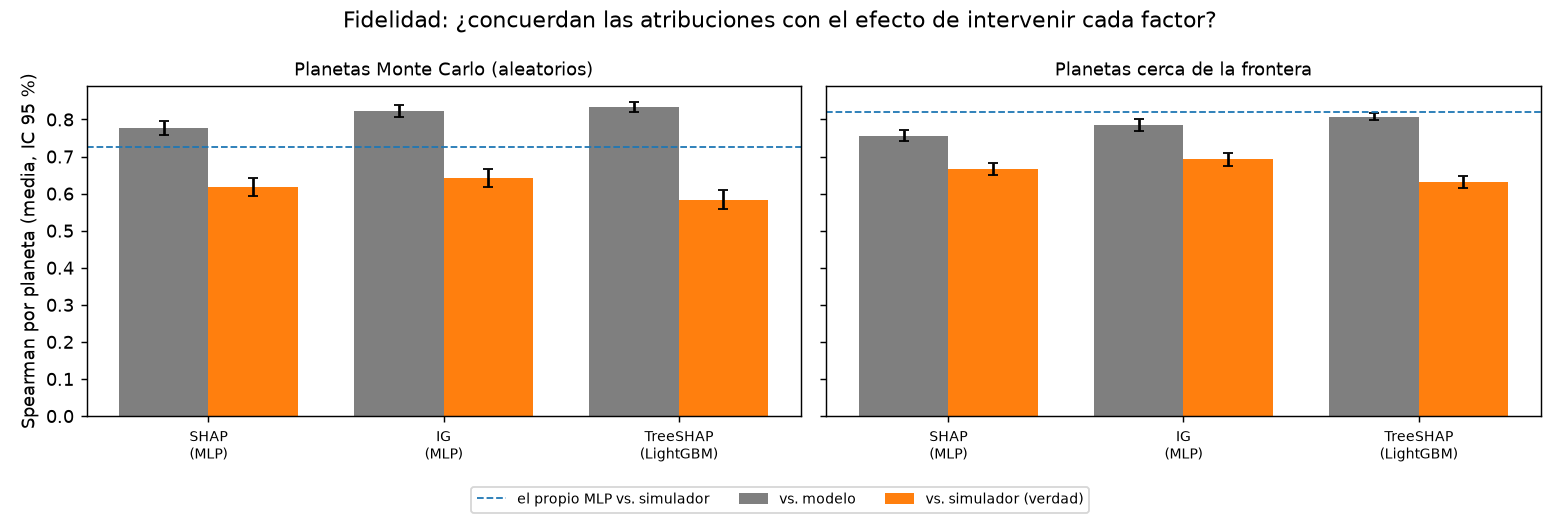

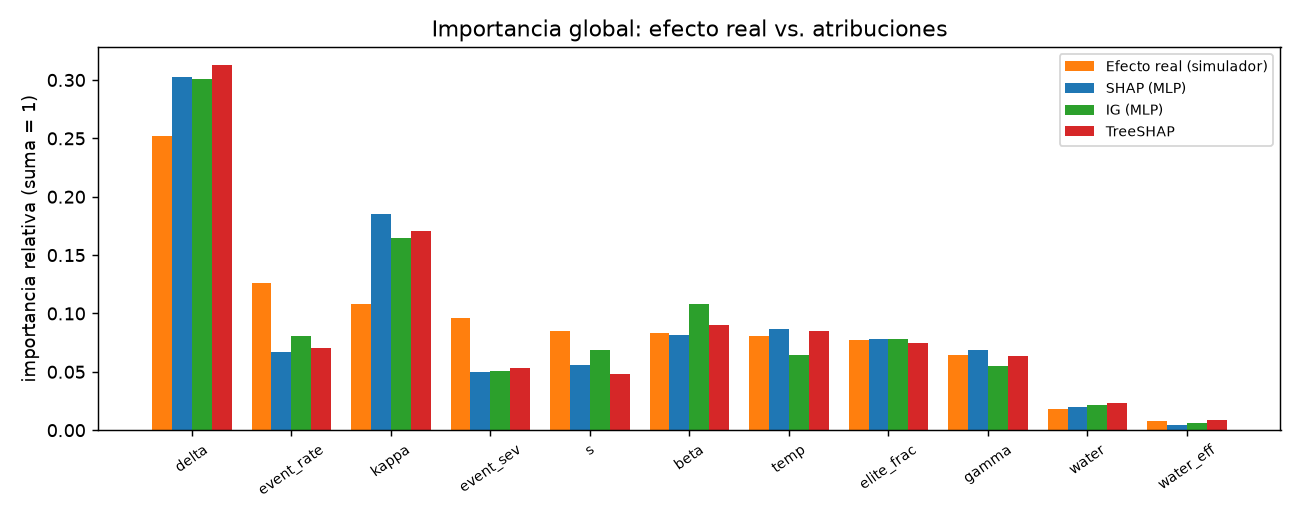

In [3]:
display(Image('report/figures/fig_fidelidad_spearman.png')); display(Image('report/figures/fig_fidelidad_global.png'))

## Curvas de eliminación y dispersión

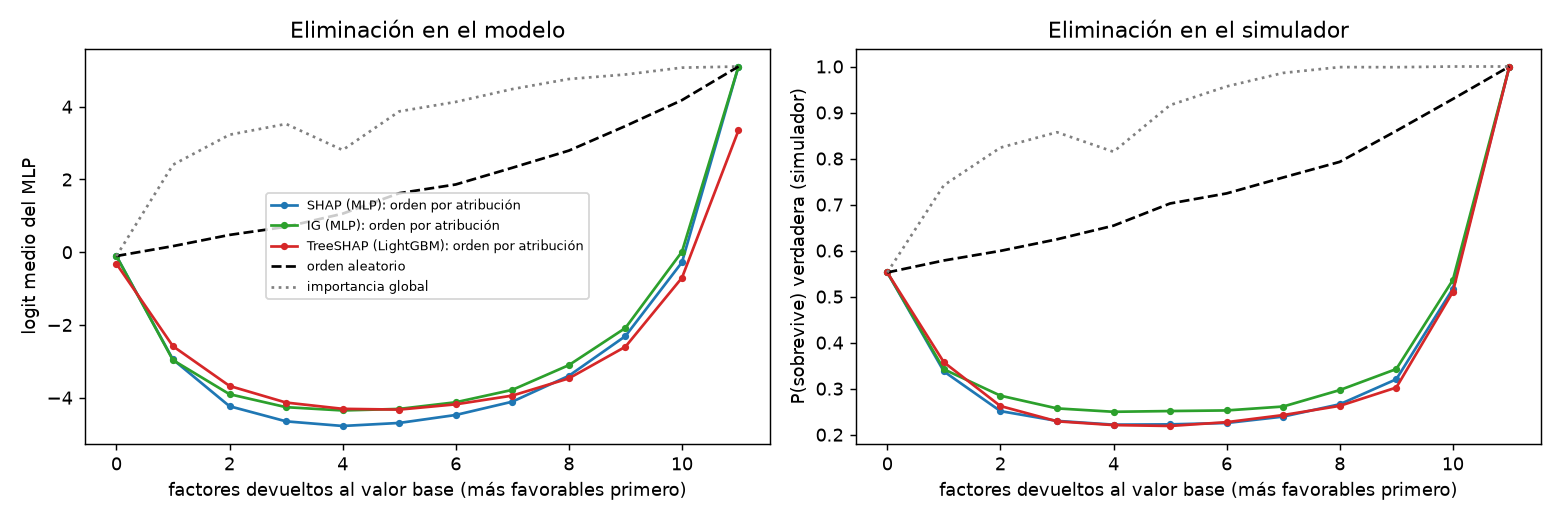

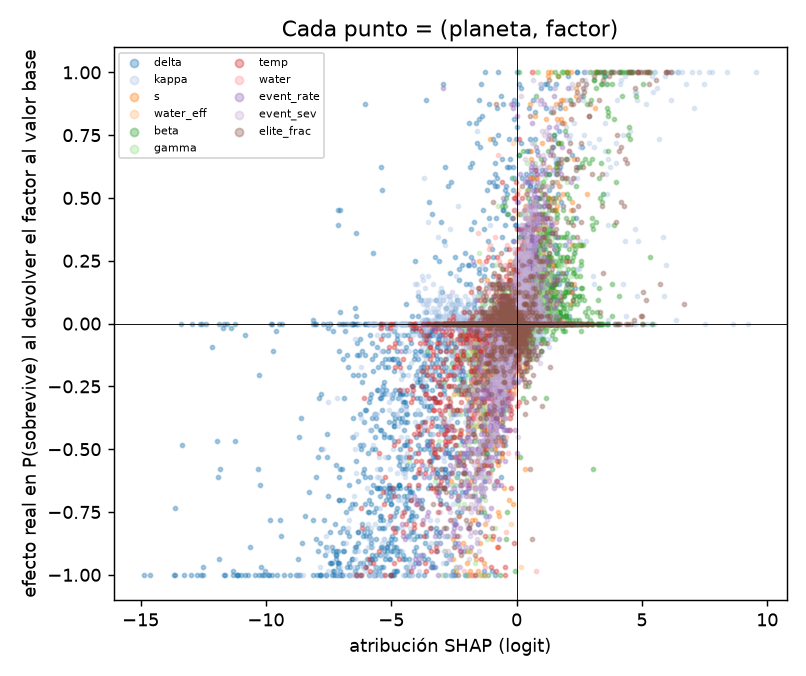

In [4]:
display(Image('report/figures/fig_fidelidad_eliminacion.png')); display(Image('report/figures/fig_fidelidad_dispersion.png', width=480))

## Prueba de cordura (pesos aleatorizados, Adebayo et al., 2018)

In [5]:
print('Spearman medio entre SHAP del modelo entrenado y del aleatorizado:', round(sanity['mean_spearman_trained_vs_randomised'], 3))
print('Spearman vs. simulador — modelo entrenado:', round(sanity['vs_simulator_trained']['spearman'], 3), '| modelo aleatorizado:', round(sanity['vs_simulator_randomised']['spearman'], 3))

Spearman medio entre SHAP del modelo entrenado y del aleatorizado: -0.135
Spearman vs. simulador — modelo entrenado: 0.653 | modelo aleatorizado: -0.128


## Contrafactuales sobre palancas accionables, verificados con el simulador

,Método,Resuelto,Válido en el modelo,Válido en el simulador,P real antes → después,Palancas cambiadas,Rango movido (suma)
0,Gradiente (varias palancas),100%,92%,90%,0.07 → 0.83,2.0,0.38
1,Una sola palanca (rejilla),87%,100%,89%,0.07 → 0.79,1.0,0.27


fracción de contrafactuales que modifican cada palanca: {'delta': 0.97, 'kappa': 0.58, 's': 0.34, 'water_eff': 0.09}


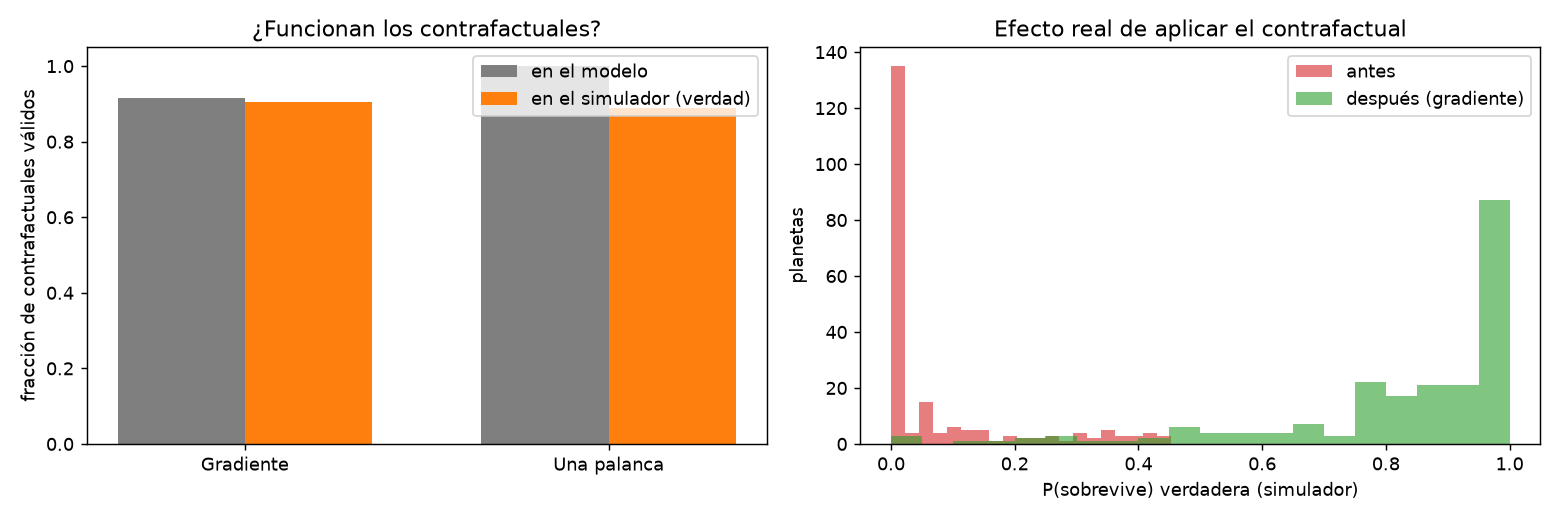

In [6]:
share = cf_figs(); display(cf_table()); print('fracción de contrafactuales que modifican cada palanca:', {k: round(v, 2) for k, v in share.items()})
display(Image('report/figures/fig_contrafactuales.png'))